# Lending Club 


Dữ liệu: Kaggle `wordsforthewise/lending-club`, file `accepted_2007_to_2018Q4.csv.gz`
(2.26 triệu khoản vay × 151 cột, 2007–2018).

## Bước 0 — Chuẩn bị

In [1]:
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=pd.errors.DtypeWarning)   # mixed-type warnings from read_csv
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)

# Find the data file: works for .csv or .csv.gz, from the repo root or from notebooks/
found = []
for folder in [Path("data/raw"), Path("../data/raw")]:
    if folder.exists():
        found += sorted(p for p in folder.rglob("accepted_2007_to_2018*.csv*") if p.is_file())
if not found:
    raise FileNotFoundError("accepted_2007_to_2018Q4 not found in data/raw or ../data/raw")
DATA_PATH = found[0]
print("Using:", DATA_PATH)

Using: ../data/raw/accepted_2007_to_2018Q4.csv


## Bước 1 — Load dữ liệu 

In [2]:
random.seed(42)
SAMPLE_SHARE = 0.10

# keep the header (row 0) and each data row with probability 10%
raw = pd.read_csv(DATA_PATH,
                  skiprows=lambda i: i > 0 and random.random() > SAMPLE_SHARE)
raw.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,...,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,Engineer,10+ years,MORTGAGE,65000.0,Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,small_business,Business,577xx,SD,16.06,1.0,Dec-1999,715.0,719.0,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,67275481,NaN,20000.0,20000.0,20000.0,36 months,8.49,631.26,B,B1,road driver,10+ years,MORTGAGE,85000.0,Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,major_purchase,Major purchase,293xx,SC,17.61,1.0,Feb-1999,705.0,709.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68616873,NaN,8000.0,8000.0,8000.0,36 months,11.48,263.74,B,B5,Vendor liaison,10+ years,MORTGAGE,42000.0,Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,credit_card,Credit card refinancing,029xx,RI,34.80,0.0,Nov-1994,700.0,704.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,68338832,NaN,1400.0,1400.0,1400.0,36 months,12.88,47.10,C,C2,Logistics Manager,3 years,MORTGAGE,64000.0,Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,other,NaN,275xx,NC,34.95,0.0,Jun-1996,700.0,704.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68495092,NaN,8650.0,8650.0,8650.0,36 months,19.89,320.99,E,E3,Program Coordinator,8 years,RENT,55000.0,Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,462xx,IN,25.49,0.0,Mar-2005,675.0,679.0,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


## Bước 2 — Kích thước (shape)

In [3]:
print("Sample shape:", raw.shape)

# Read the FULL file in chunks of 200,000 rows: only one chunk is in memory at a time.
# While reading, count rows, missing cells per column, and distinct values
# for the columns used as evidence in Step 4.
CHECK_UNIQUE = ["id", "member_id", "url", "zip_code",      # identifiers
                "emp_title", "title", "desc",              # free text
                "policy_code", "pymnt_plan"]               # constant

n_rows = 0
missing_count = None
unique_values = {c: set() for c in CHECK_UNIQUE}

for chunk in pd.read_csv(DATA_PATH, chunksize=200_000):
    n_rows += len(chunk)
    counts = chunk.isna().sum()
    missing_count = counts if missing_count is None else missing_count + counts
    for c in CHECK_UNIQUE:
        unique_values[c].update(chunk[c].dropna().unique())

print("Full file shape:", (n_rows, len(missing_count)))

Sample shape: (226452, 151)
Full file shape: (2260701, 151)


## Bước 3 — Xem các feature

Một bảng cho từng cột: kiểu dữ liệu, % bị thiếu, số giá trị khác nhau và một giá trị ví dụ.

In [4]:
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),                                  # from the sample
    "missing_%": (missing_count / n_rows * 100).round(1),             # FULL file
    "n_unique": raw.nunique(),                                        # sample, replaced below
    "example": raw.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
})
for c in CHECK_UNIQUE:                                                # FULL file for these columns
    overview.loc[c, "n_unique"] = len(unique_values[c])

print(overview["dtype"].value_counts(), "\n")
overview

dtype
float64    113
str         37
object       1
Name: count, dtype: int64 



,dtype,missing_%,n_unique,example
id,object,0.0,2260701,68355089
member_id,float64,100.0,0,None
loan_amnt,float64,0.0,1511,24700.0
funded_amnt,float64,0.0,1511,24700.0
funded_amnt_inv,float64,0.0,2365,24700.0
term,str,0.0,2,36 months
int_rate,float64,0.0,614,11.99
installment,float64,0.0,43052,820.28
grade,str,0.0,7,C
sub_grade,str,0.0,35,C1


In [5]:
print("Columns more than 90% missing:", (overview["missing_%"] > 90).sum())
print("Columns with no missing value:", (overview["missing_%"] == 0).sum())
print("\nMore than 90% missing:")
print(overview.loc[overview["missing_%"] > 90, "missing_%"].sort_values(ascending=False).to_string())

Columns more than 90% missing: 38
Columns with no missing value: 52

More than 90% missing:
member_id                                     100.0
orig_projected_additional_accrued_interest     99.6
hardship_reason                                99.5
hardship_status                                99.5
hardship_type                                  99.5
hardship_start_date                            99.5
hardship_loan_status                           99.5
hardship_dpd                                   99.5
hardship_length                                99.5
payment_plan_start_date                        99.5
hardship_amount                                99.5
hardship_end_date                              99.5
hardship_last_payment_amount                   99.5
deferral_term                                  99.5
hardship_payoff_balance_amount                 99.5
settlement_date                                98.5
settlement_percentage                          98.5
settlement_term         

## Bước 4 — Chọn feature

### 4a — Mã định danh: không mang thông tin rủi ro

`id` và `url` khác nhau ở mọi khoản vay; `member_id` trống. `zip_code` chỉ có 3 chữ số đầu và
là biến đại diện quen thuộc cho chủng tộc / sắc tộc, nên dùng nó sẽ gây vấn đề công bằng.

In [7]:
IDENTIFIERS = ["id", "member_id", "url", "zip_code"]
overview.loc[IDENTIFIERS, ["missing_%", "n_unique", "example"]]

,missing_%,n_unique,example
id,0.0,2260701,68355089
member_id,100.0,0,None
url,0.0,2260668,https://lendingclub.com/browse/loanDetail.acti...
zip_code,0.0,956,577xx


### 4b — Văn bản tự do: hàng chục nghìn giá trị khác nhau

In [8]:
FREE_TEXT = ["emp_title", "title", "desc"]
overview.loc[FREE_TEXT, ["missing_%", "n_unique", "example"]]

,missing_%,n_unique,example
emp_title,7.4,512694,Engineer
title,1.0,63154,Business
desc,94.4,124500,i recently proposed to my girlfriend of almost...


**Nhận xét:** `emp_title` có hàng chục nghìn chức danh khác nhau ngay cả trong mẫu 10%, còn
`desc` gần như luôn trống. Muốn dùng phải xử lý ngôn ngữ (NLP), nằm ngoài phạm vi project.

### 4c — Cột hằng số: (gần như) cùng một giá trị cho mọi khoản vay

In [9]:
CONSTANT = ["policy_code", "pymnt_plan"]
for col in CONSTANT:
    print(pd.read_csv(DATA_PATH, usecols=[col])[col].value_counts(dropna=False), "\n")

policy_code
1.0    2260668
NaN         33
Name: count, dtype: int64 

pymnt_plan
n      2260048
y          620
NaN         33
Name: count, dtype: int64 



### 4d — Cột của hồ sơ vay chung: trống với hồ sơ cá nhân

In [10]:
JOINT = [c for c in raw.columns if c.endswith("_joint") or c.startswith("sec_app_")]
print(raw["application_type"].value_counts(normalize=True).round(3), "\n")
overview.loc[JOINT, ["missing_%"]].sort_values("missing_%")

application_type
Individual    0.947
Joint App     0.053
Name: proportion, dtype: float64 



,missing_%
annual_inc_joint,94.7
dti_joint,94.7
verification_status_joint,94.9
revol_bal_joint,95.2
sec_app_fico_range_low,95.2
sec_app_fico_range_high,95.2
sec_app_earliest_cr_line,95.2
sec_app_inq_last_6mths,95.2
sec_app_mort_acc,95.2
sec_app_open_acc,95.2


**Nhận xét:** chỉ khoảng 5% hồ sơ là vay chung, nên 16 cột này trống hơn 90%.

### 4e — Leakage: các cột chỉ tồn tại *sau khi* đã cho vay

In [11]:
# Columns that only exist AFTER the loan was given (payments, recoveries, hardship,
# settlement, post-funding amounts). They cannot be known at application -> leakage.
POST_LOAN = sorted(
    ["total_rec_prncp", "total_rec_int", "total_rec_late_fee", "total_pymnt", "total_pymnt_inv",
     "last_pymnt_d", "last_pymnt_amnt", "next_pymnt_d", "last_credit_pull_d",
     "recoveries", "collection_recovery_fee", "out_prncp", "out_prncp_inv",
     "last_fico_range_high", "last_fico_range_low", "funded_amnt", "funded_amnt_inv",
     "debt_settlement_flag", "debt_settlement_flag_date", "disbursement_method",
     "deferral_term", "payment_plan_start_date", "orig_projected_additional_accrued_interest"]
    + [c for c in raw.columns if c.startswith(("hardship_", "settlement_"))])
print(len(POST_LOAN), "post-loan (leakage) columns:")
print(POST_LOAN)

40 post-loan (leakage) columns:
['collection_recovery_fee', 'debt_settlement_flag', 'debt_settlement_flag_date', 'deferral_term', 'disbursement_method', 'funded_amnt', 'funded_amnt_inv', 'hardship_amount', 'hardship_dpd', 'hardship_end_date', 'hardship_flag', 'hardship_last_payment_amount', 'hardship_length', 'hardship_loan_status', 'hardship_payoff_balance_amount', 'hardship_reason', 'hardship_start_date', 'hardship_status', 'hardship_type', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'last_pymnt_amnt', 'last_pymnt_d', 'next_pymnt_d', 'orig_projected_additional_accrued_interest', 'out_prncp', 'out_prncp_inv', 'payment_plan_start_date', 'recoveries', 'settlement_amount', 'settlement_date', 'settlement_percentage', 'settlement_status', 'settlement_term', 'total_pymnt', 'total_pymnt_inv', 'total_rec_int', 'total_rec_late_fee', 'total_rec_prncp']


**Nhận xét:** đứng một mình, các cột sau khi vay đã đạt ROC-AUC **0.86–0.92**
(`last_fico_range_*` 0.92, `recoveries` 0.88, `total_rec_prncp` 0.86), trong khi cột tốt nhất
có lúc nộp đơn là `int_rate` chỉ đạt **0.68**. Gộp các cột này lại, mô hình có thể đạt gần
0.99 — nhưng vô dụng ngoài thực tế, vì nó đang đọc đáp án. (`out_prncp` bằng 0 với
mọi khoản đã kết thúc nên ở đây không mang tín hiệu — nhưng rõ ràng là trường sau khi vay.)

Một số cột leakage là chữ hoặc ngày chứ không phải số. Bảng chéo đơn giản cho thấy cùng
một điều:

In [12]:
print("Default rate by debt_settlement_flag (Y = loan went to a settlement agency):")
print(fin.groupby("debt_settlement_flag")["target"].agg(["mean", "size"]).round(3), "\n")

print("Share of loans with a hardship plan, by loan status (whole sample):")
print(raw.groupby("loan_status")["hardship_flag"].apply(lambda s: (s == "Y").mean()).round(3), "\n")

print("next_pymnt_d is missing for finished loans (it only exists while a loan is running):")
print(round(fin["next_pymnt_d"].isna().mean(), 3), "\n")

print("funded_amnt equals the requested loan_amnt for this share of loans:")
print(round((raw["funded_amnt"] == raw["loan_amnt"]).mean(), 4))

Default rate by debt_settlement_flag (Y = loan went to a settlement agency):
                       mean   size
debt_settlement_flag              
N                     0.166  81038
Y                     1.000   1806 

Share of loans with a hardship plan, by loan status (whole sample):
loan_status
Charged Off                                            0.000
Current                                                0.000
Default                                                0.000
Does not meet the credit policy. Status:Charged Off    0.000
Does not meet the credit policy. Status:Fully Paid     0.000
Fully Paid                                             0.000
In Grace Period                                        0.001
Late (16-30 days)                                      0.030
Late (31-120 days)                                     0.040
Name: hardship_flag, dtype: float64 

next_pymnt_d is missing for finished loans (it only exists while a loan is running):
1.0 

funded_amnt equals the 

**Nhận xét:** cờ tất toán bằng `Y` thì khoản vay **luôn** vỡ nợ (100%); gói hỗ trợ khó khăn
(hardship) **chỉ** xuất hiện ở khoản vay đang trễ hạn (3–4% khoản trễ hạn, 0% khoản đã kết
thúc) — đó là phản ứng khi đã gặp khó khăn, không thể biết lúc nộp đơn; `next_pymnt_d` chỉ có khi khoản vay còn đang chạy; `funded_amnt` được quyết định *sau khi* duyệt và gần như luôn bằng
`loan_amnt` mà người vay xin, nên giữ `loan_amnt` thay vì nó.

In [14]:
# Columns that only exist AFTER the loan was given -> leakage, removed
POST_LOAN = sorted(set(
    ["total_rec_prncp", "total_rec_int", "total_rec_late_fee", "total_pymnt", "total_pymnt_inv",
     "last_pymnt_d", "last_pymnt_amnt", "next_pymnt_d", "last_credit_pull_d",
     "recoveries", "collection_recovery_fee", "out_prncp", "out_prncp_inv",
     "last_fico_range_high", "last_fico_range_low", "funded_amnt", "funded_amnt_inv",
     "debt_settlement_flag", "debt_settlement_flag_date", "disbursement_method",
     "deferral_term", "payment_plan_start_date", "orig_projected_additional_accrued_interest"]
    + [c for c in raw.columns if c.startswith(("hardship_", "settlement_"))]))
print(len(POST_LOAN), "post-loan (leakage) columns")

40 post-loan (leakage) columns


### 4f — Các cột bureau 


In [ ]:
BUREAU_EXTRA = sorted(
    [c for c in raw.columns if c.startswith(("mo_sin_", "num_", "mths_since_recent_"))]
    + ["all_util", "il_util", "inq_fi", "inq_last_12m", "max_bal_bc", "open_acc_6m",
       "open_il_12m", "open_il_24m", "open_act_il", "open_rv_12m", "open_rv_24m",
       "total_bal_il", "total_cu_tl", "total_rev_hi_lim", "acc_open_past_24mths",
       "avg_cur_bal", "bc_open_to_buy", "bc_util", "percent_bc_gt_75", "pct_tl_nvr_dlq",
       "tot_coll_amt", "tot_cur_bal", "tot_hi_cred_lim", "total_bal_ex_mort",
       "total_bc_limit", "total_il_high_credit_limit", "mths_since_rcnt_il"])
print(len(BUREAU_EXTRA), "extra bureau columns\n")

first_month = {c: raw.loc[raw[c].notna(), "issue_d"].min() for c in BUREAU_EXTRA}
print("First month with a value -> number of columns:")
print(pd.Series(first_month).dt.strftime("%Y-%m").value_counts().sort_index(), "\n")

raw.groupby(raw["issue_d"].dt.year)[["bc_util", "tot_cur_bal", "il_util", "all_util"]] \
   .apply(lambda g: g.isna().mean()).round(2)

49 extra bureau columns

First month with a value -> number of columns:
2012-03     9
2012-06     2
2012-08    24
2015-12    14
Name: count, dtype: int64 



,bc_util,tot_cur_bal,il_util,all_util
issue_d,,,,
2007,1.00,1.00,1.00,1.00
2008,1.00,1.00,1.00,1.00
2009,1.00,1.00,1.00,1.00
2010,1.00,1.00,1.00,1.00
2011,1.00,1.00,1.00,1.00
2012,0.15,0.52,1.00,1.00
2013,0.01,0.00,1.00,1.00
2014,0.01,0.00,1.00,1.00
2015,0.01,0.00,0.96,0.95


**Nhận xét:** phần lớn các cột này bắt đầu từ 2012, một số chỉ từ tháng 12/2015. Giai đoạn
train bắt đầu từ 2007, nên nhóm chỉ giữ những cột có dữ liệu suốt cả giai đoạn. (Phần lớn cột
từ 2012 sẽ dùng được nếu train bắt đầu từ 2012 — một hướng mở rộng.)

### 4g — Sự kiện hiếm: gần như luôn bằng 0 hoặc trống

In [ ]:
RARE = ["acc_now_delinq", "delinq_amnt", "chargeoff_within_12_mths",
        "collections_12_mths_ex_med", "tax_liens",
        "mths_since_last_record", "mths_since_last_major_derog"]
pd.DataFrame({
    "share_zero_%": [round((raw[c] == 0).mean() * 100, 1) for c in RARE],
    "missing_%": overview.loc[RARE, "missing_%"].values,
}, index=RARE)

,share_zero_%,missing_%
acc_now_delinq,99.6,0.0
delinq_amnt,99.7,0.0
chargeoff_within_12_mths,99.2,0.0
collections_12_mths_ex_med,98.3,0.0
tax_liens,97.1,0.0
mths_since_last_record,0.1,84.1
mths_since_last_major_derog,0.0,74.3


**Nhận xét:** năm cột đầu bằng 0 với gần như mọi khoản vay; hai cột cuối trống ở phần lớn khoản
vay. Quá ít trường hợp khác 0 để học được gì.

### 4h — Những gì được giữ lại

In [ ]:
KEEP = ["loan_amnt", "term", "int_rate", "installment", "grade", "sub_grade", "purpose",
        "initial_list_status", "application_type", "emp_length", "home_ownership",
        "annual_inc", "verification_status", "addr_state", "dti", "delinq_2yrs",
        "earliest_cr_line", "fico_range_low", "fico_range_high", "inq_last_6mths",
        "mths_since_last_delinq", "open_acc", "pub_rec", "revol_bal", "revol_util",
        "total_acc", "mort_acc", "pub_rec_bankruptcies", "issue_d"]
TARGET = ["loan_status"]

groups = {"kept": KEEP, "target": TARGET, "post-loan (leakage)": POST_LOAN,
          "bureau, empty before 2012": BUREAU_EXTRA, "joint application": JOINT,
          "rare event": RARE, "identifier": IDENTIFIERS, "free text": FREE_TEXT,
          "constant": CONSTANT}

all_listed = [c for cols in groups.values() for c in cols]
assert len(all_listed) == len(set(all_listed)), "a column is in two groups"
assert set(all_listed) == set(raw.columns), set(raw.columns) ^ set(all_listed)
print("OK - all", len(raw.columns), "columns are in exactly one group\n")

pd.Series({g: len(c) for g, c in groups.items()}, name="columns")

OK - all 151 columns are in exactly one group



kept                         29
target                        1
post-loan (leakage)          40
bureau, empty before 2012    49
joint application            16
rare event                    7
identifier                    4
free text                     3
constant                      2
Name: columns, dtype: int64

**Nhận xét:** **151 cột → 29 feature + 1 biến mục tiêu.** Mỗi cột bị bỏ đều có lý do được
chứng minh ở trên; lệnh `assert` sẽ báo lỗi nếu quên một cột nào.

In [ ]:
del raw, fin   # free memory before loading the full file

## Bước 5 — Load toàn bộ file 

In [ ]:
df = pd.read_csv(DATA_PATH, usecols=KEEP + TARGET)
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y", errors="coerce")
df = df.dropna(subset=["issue_d"])
print("Shape:", df.shape)
df["loan_status"].value_counts()

Shape: (2260668, 30)


loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64

**Nhận xét:** `loan_status` có 9 giá trị, nhưng chỉ ba giá trị là **kết quả cuối cùng**:
- `Fully Paid` → đã trả hết → **0**
- `Charged Off`, `Default` → người vay ngừng trả (trễ khoảng 4–5 tháng) → **1**
- `Current`, `Late …`, `In Grace Period` → khoản vay **còn đang chạy**: chưa biết kết quả, nên
  không dùng được.
- `Does not meet the credit policy …` → khoản vay cũ theo chính sách khác; cũng bỏ.

Kiểm tra mỗi năm số % khoản vay kết thúc

In [ ]:
FINAL = ["Fully Paid", "Charged Off", "Default"]
is_final = df["loan_status"].isin(FINAL)

# Before removing them: which share of loans is finished, by issue year?
is_final.groupby(df["issue_d"].dt.year).mean().round(3)

issue_d
2007    0.416
2008    0.653
2009    0.893
2010    0.920
2011    1.000
2012    1.000
2013    1.000
2014    0.947
2015    0.892
2016    0.675
2017    0.382
2018    0.114
Name: loan_status, dtype: float64

**Nhận xét:** khoản vay đến 2013 (gần như) đều đã kết thúc, nhưng năm 2018 chỉ **11%**. Một
khoản 2018 chỉ "đã kết thúc" nếu nó kết thúc **sớm** (vỡ nợ sớm hoặc trả trước hạn), nên các
năm gần đây không phải mẫu bình thường 

In [ ]:
df = df[is_final].copy()
df["target"] = df["loan_status"].isin(["Charged Off", "Default"]).astype(int)
df = df.drop(columns=["loan_status"])
print("Rows kept:", len(df))

Rows kept: 1345350


## Bước 6 — Tỷ lệ vỡ nợ

target
0    1076751
1     268599
Name: count, dtype: int64

Default rate: 0.1996


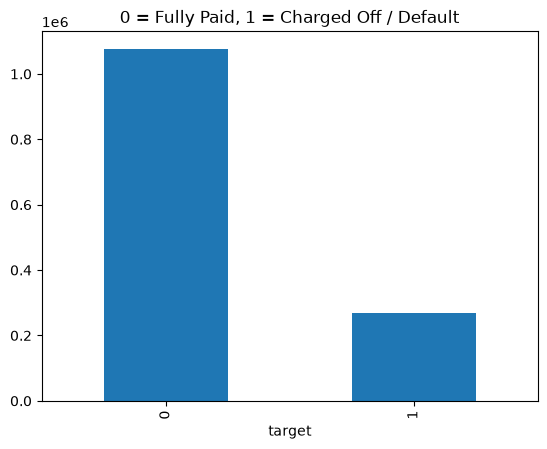

In [ ]:
print(df["target"].value_counts())
print("\nDefault rate:", round(df["target"].mean(), 4))

df["target"].value_counts().plot(kind="bar", title="0 = Fully Paid, 1 = Charged Off / Default")
plt.show()

**Nhận xét:** khoảng **1/5** khoản vay vỡ nợ (19.96%). Dữ liệu mất cân bằng nên **accuracy gây
